# N158 · Longer-stream learning-rate MPC

Queued after N157. N157's scientific result is independent of this run's start.

## Decisions and comparisons

- Two ordered 48-clip BDD development streams, 96 chronological frames per clip.
  Fill 128 past frames before decisions. Each arm gets 4,480 decisions per
  stream, or 8,960 across both. Train on one current image per accepted decision.
  The bank supplies health observations. Each path starts from the same earlier
  warm RGB64 MAE and a fresh AdamW optimizer.
- MPC considers 0, 1/16 and 1/4 of nominal LR 0.0001 over two arrivals. Run strict
  current-loss MPC, calibrated current-loss MPC, and calibrated 50/50 current
  and bank-loss MPC. Baselines accept every post-fill image at nominal or quarter
  rate. LR dose and gradient work are outcomes of the policy.
- Freeze an eight-frame assay at each origin. It contains the arriving frame
  and seven past frames of ages 1, 4, 12, 24, 48, 80 and 128. Fixed-mask loss is
  measured on the current image and past bank. RankMe and variance use the
  contextual embedding matrix with the incoming image included. A single
  embedding cannot provide a useful spectrum by itself.
- Predict H1 and H2 health on that same origin assay. Plans state future rates
  for whatever arrives. The predictor receives current and past features only.
  The selected first step is executed, then planning repeats at the next arrival.
  Skip leaves the learner and its optimizer unchanged.
- A positive first step and the terminal forecast require a loss decrease greater
  than 0.001 and strictly positive RankMe gain. A deferred first step preserves
  H1 health. The second step may preserve or improve H1 health. Calibrated arms subtract one-sided error margins from gains. The
  mixed arm also guards current-image loss. Among eligible plans minimize
  predicted loss / current loss + current RankMe / predicted RankMe. If none
  qualify, skip. Forecast constraints are checked against measured outcomes.

## Training and measurements

Use 16 archived training videos for paired offline fitting, eight separate videos
for calibration, and eight for offline testing. Collect all nine two-step plans
at deterministic origins. Score on the fixed origin assay after sequentially
revealing the next frame. Fit direct ridge heads for physical rate or rate pair.
Calibrate 90th-percentile overprediction margins before any online data. All
three MPCs adapt only from the measured chosen H1 action and realized H2 action
pair with at least one update. The offline scaling and margins stay fixed.

Every arm also runs a simple next-arrival H1 predictor. Each metric has its own
scalar autoregression from the previous image's pre-update reading to the next.
It starts from last-value persistence and learns only after the next reading is
measured. The forecast uses no action, image features or other metrics. This
forecast is issued before the next frame is seen and is scored separately from
the action-conditioned MPC forecasts. RankMe and variance refer to the next
arrival's contextual panel. The simple predictor does not control the learner.

During deployment, compare H1 and realized-pair H2 forecasts against persistence
on identical observed targets. Show positive-update RMSE separately, every
accepted image's actual augmented training loss, action counts, observed health
violations, and independent audit and scene-probe results at a fixed clip grid.
Per-clip JSON ledgers retain all offered-image identities and loss readings,
and distinguish planned from executed second steps. Training loss also exports
to CSV on completion of each trajectory.

Offline, deployment and audit videos are clip-disjoint and checked for exact
pixel overlap. These are reused local development archives. Capture-session
independence is unknown. The audit reports by lighting. Labels are used only
for the held-out scene probe. Leave at least 3 GiB free throughout.


## Live status

**complete** · All five arms and matched forecast comparisons saved

Updated UTC `2026-11-06T15:08:36+00:00` · PID `31344`.

N157 status **complete**. Its qualification result does not gate N158.

All 44,800 deployment decisions are complete.

Free disk **19.4 GiB**, with a 3 GiB reserve.

## Deployment coverage and observed training

| Stream / arm | Decisions | Skip | 1/16 | 1/4 | Nominal | Train loss mean | Pre-loss mean | Latest balanced audit loss | Scene accuracy |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| pool_1/full_admission | 4,480 | 0 | 0 | 0 | 4,480 | 0.81082 | 0.83078 | 1.12129 | 45.11% |
| pool_1/quarter_admission | 4,480 | 0 | 0 | 4,480 | 0 | 0.81748 | 0.83914 | 0.89395 | 40.94% |
| pool_1/mpc_strict_current | 4,480 | 3,573 | 0 | 907 | 0 | 0.82265 | 0.86764 | 0.88554 | 40.72% |
| pool_1/mpc_calibrated_current | 4,480 | 4,480 | 0 | 0 | 0 | — | 0.86364 | 0.87047 | 41.22% |
| pool_1/mpc_calibrated_mixed | 4,480 | 4,480 | 0 | 0 | 0 | — | 0.86364 | 0.87047 | 41.22% |
| pool_2/full_admission | 4,480 | 0 | 0 | 0 | 4,480 | 0.83127 | 0.84920 | 1.14558 | 38.72% |
| pool_2/quarter_admission | 4,480 | 0 | 0 | 4,480 | 0 | 0.82830 | 0.84776 | 0.88848 | 41.56% |
| pool_2/mpc_strict_current | 4,480 | 4,080 | 0 | 400 | 0 | 0.86422 | 0.87405 | 0.88200 | 42.11% |
| pool_2/mpc_calibrated_current | 4,480 | 4,480 | 0 | 0 | 0 | — | 0.86882 | 0.87047 | 41.22% |
| pool_2/mpc_calibrated_mixed | 4,480 | 4,480 | 0 | 0 | 0 | — | 0.86882 | 0.87047 | 41.22% |

## Simple next-arrival H1 forecast

Each cell is online scalar forecast / last-value persistence RMSE on the same next arrivals.

| Stream / arm | Cases | Current loss | Bank loss | RankMe | Variance |
|---|---:|---:|---:|---:|---:|
| pool_1/full_admission | 4,479 | 0.04327 / 0.043619 | 0.015347 / 0.01535 | 0.049661 / 0.049632 | 0.031339 / 0.031273 |
| pool_1/quarter_admission | 4,479 | 0.036821 / 0.037076 | 0.014334 / 0.014345 | 0.055509 / 0.055554 | 0.020752 / 0.02066 |
| pool_1/mpc_strict_current | 4,479 | 0.039744 / 0.04008 | 0.015263 / 0.015279 | 0.054303 / 0.05437 | 0.02308 / 0.023076 |
| pool_1/mpc_calibrated_current | 4,479 | 0.02919 / 0.029402 | 0.010936 / 0.010938 | 0.053388 / 0.053428 | 0.01907 / 0.019066 |
| pool_1/mpc_calibrated_mixed | 4,479 | 0.02919 / 0.029402 | 0.010936 / 0.010938 | 0.053388 / 0.053428 | 0.01907 / 0.019066 |
| pool_2/full_admission | 4,479 | 0.047013 / 0.047527 | 0.01559 / 0.015631 | 0.05118 / 0.051215 | 0.026046 / 0.026055 |
| pool_2/quarter_admission | 4,479 | 0.038971 / 0.039351 | 0.014328 / 0.014358 | 0.059638 / 0.059682 | 0.024342 / 0.024362 |
| pool_2/mpc_strict_current | 4,479 | 0.035253 / 0.035635 | 0.013605 / 0.013635 | 0.058639 / 0.05866 | 0.021364 / 0.021368 |
| pool_2/mpc_calibrated_current | 4,479 | 0.029523 / 0.029741 | 0.011093 / 0.011103 | 0.055669 / 0.055654 | 0.01836 / 0.01836 |
| pool_2/mpc_calibrated_mixed | 4,479 | 0.029523 / 0.029741 | 0.011093 / 0.011103 | 0.055669 / 0.055654 | 0.01836 / 0.01836 |

## Forecast RMSE on observed positive updates

Each cell is forecast / persistence RMSE. H2 uses the actual rate pair and the same origin panel. The realized second action can differ from the original plan.

| Stream / arm | Horizon | Cases | Current loss | Bank loss | RankMe | Variance | Threshold misses / loss rose / rank fell |
|---|---|---:|---:|---:|---:|---:|---:|
| pool_1/mpc_strict_current | H1 | 907 | 0.0025542 / 0.0030276 | 0.0012472 / 0.0015017 | 0.0040062 / 0.0042588 | 0.0025715 / 0.0026311 | 689 / 173 / 530 |
| pool_1/mpc_strict_current | H2 | 1,024 | 0.0046858 / 0.0055227 | 0.0022626 / 0.0026545 | 0.0074763 / 0.0077311 | 0.0047012 / 0.0046578 | 736 / 190 / 610 |
| pool_2/mpc_strict_current | H1 | 400 | 0.0017348 / 0.0021009 | 0.00084844 / 0.0010858 | 0.0046685 / 0.0051876 | 0.0020803 / 0.0023338 | 310 / 74 / 226 |
| pool_2/mpc_strict_current | H2 | 506 | 0.0028951 / 0.0034943 | 0.0014539 / 0.0018222 | 0.0081094 / 0.0087578 | 0.003596 / 0.0038666 | 386 / 90 / 300 |

## Offline held-out forecast test

106 origins. RMSE entries are forecast / persistence across positive actions or nonzero pairs.

| Horizon | Current loss | Bank loss | RankMe | Variance |
|---|---:|---:|---:|---:|
| H1 | 0.002051 / 0.0022758 | 0.00080382 / 0.00091378 | 0.0037839 / 0.0040312 | 0.0022488 / 0.0023214 |
| H2 | 0.0032263 / 0.0035621 | 0.0011776 / 0.0013361 | 0.0056351 / 0.0060131 | 0.0034214 / 0.0035322 |

## Final equal-pool comparison

| Arm | Mean incoming loss | Final audit loss | Final audit RankMe | Final scene accuracy | Updates | LR dose |
|---|---:|---:|---:|---:|---:|---:|
| full_admission | 0.839992 | 1.133434 | 1.64561 | 41.917% | 8,960 | 8960.00 |
| quarter_admission | 0.843449 | 0.891214 | 2.45926 | 41.250% | 8,960 | 2240.00 |
| mpc_strict_current | 0.870844 | 0.883770 | 2.33584 | 41.417% | 1,307 | 326.75 |
| mpc_calibrated_current | 0.866227 | 0.870475 | 2.38705 | 41.222% | 0 | 0.00 |
| mpc_calibrated_mixed | 0.866227 | 0.870475 | 2.38705 | 41.222% | 0 | 0.00 |

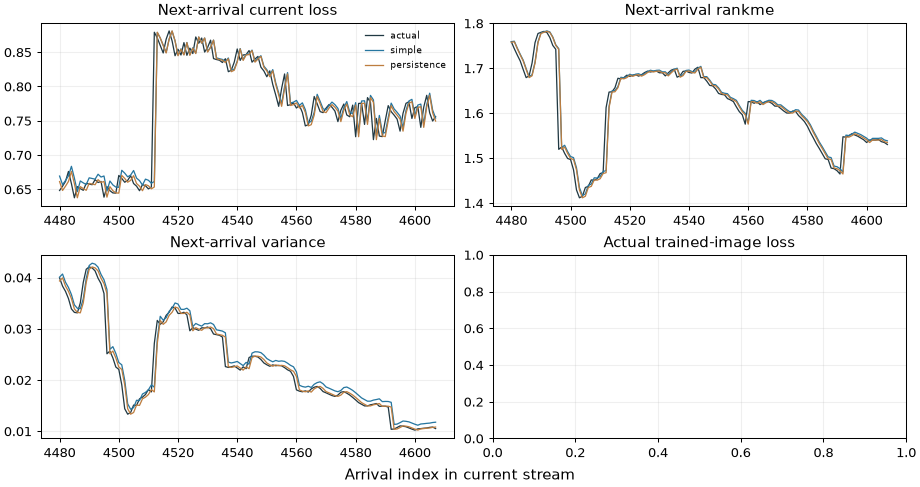

## Full-run trajectories

Actual loss and RankMe are separate from forecast RMSE. Training loss is averaged over accepted images in each clip. All-skipping arms have no training loss. Action-forecast RMSE uses positive H1 actions or nonzero realized H2 pairs. The per-image ledgers are retained.

### Observed incoming loss, training loss and RankMe

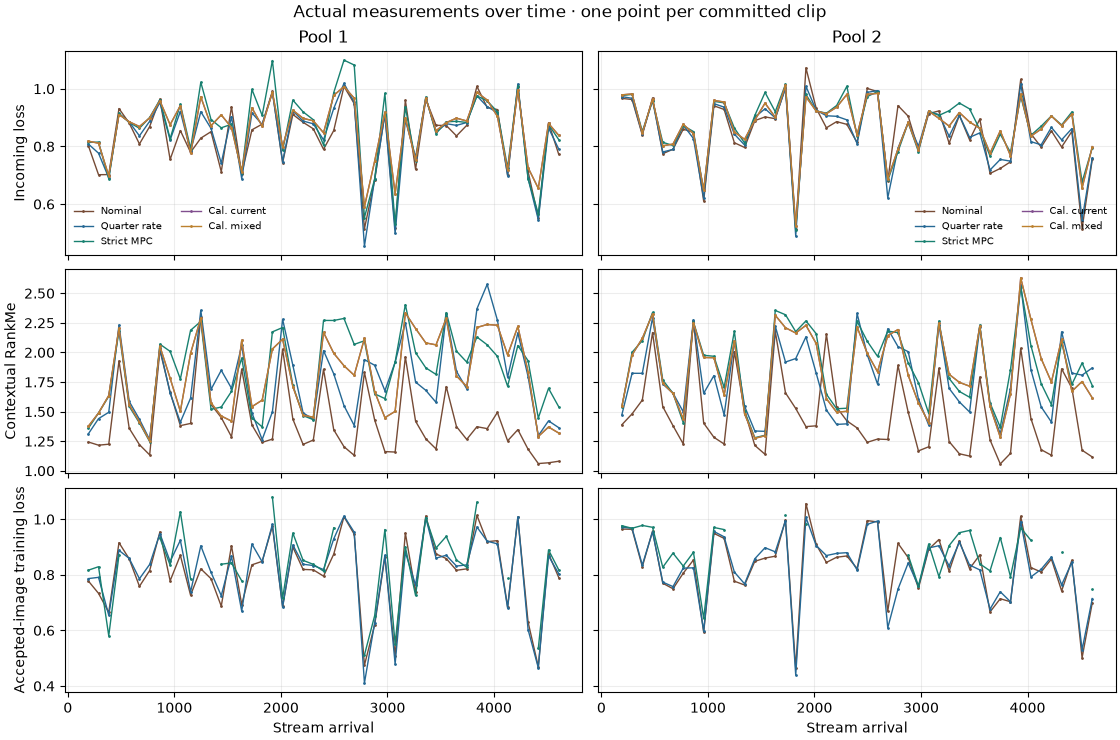

### Independent audit loss and RankMe

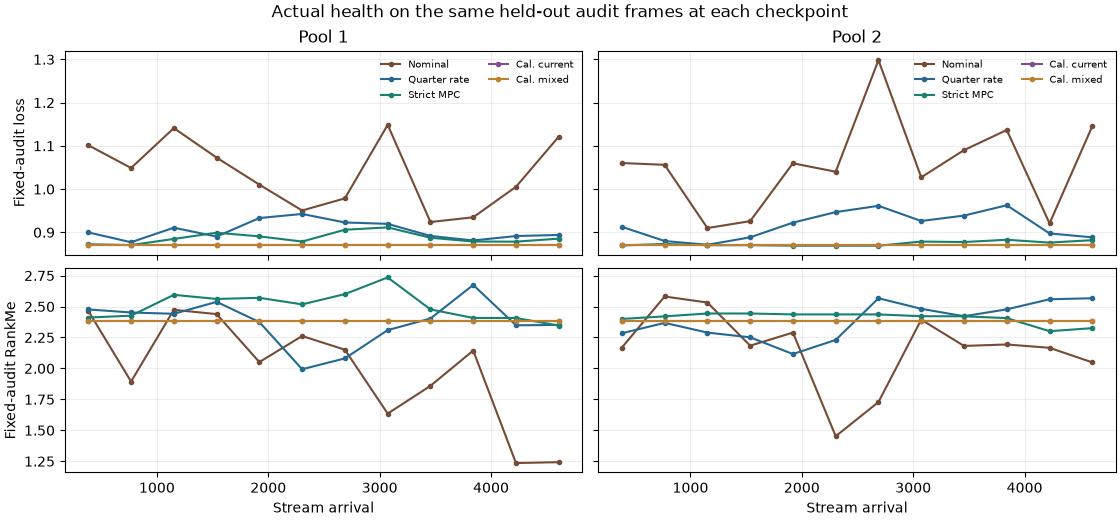

### Simple H1 next-arrival RMSE against persistence

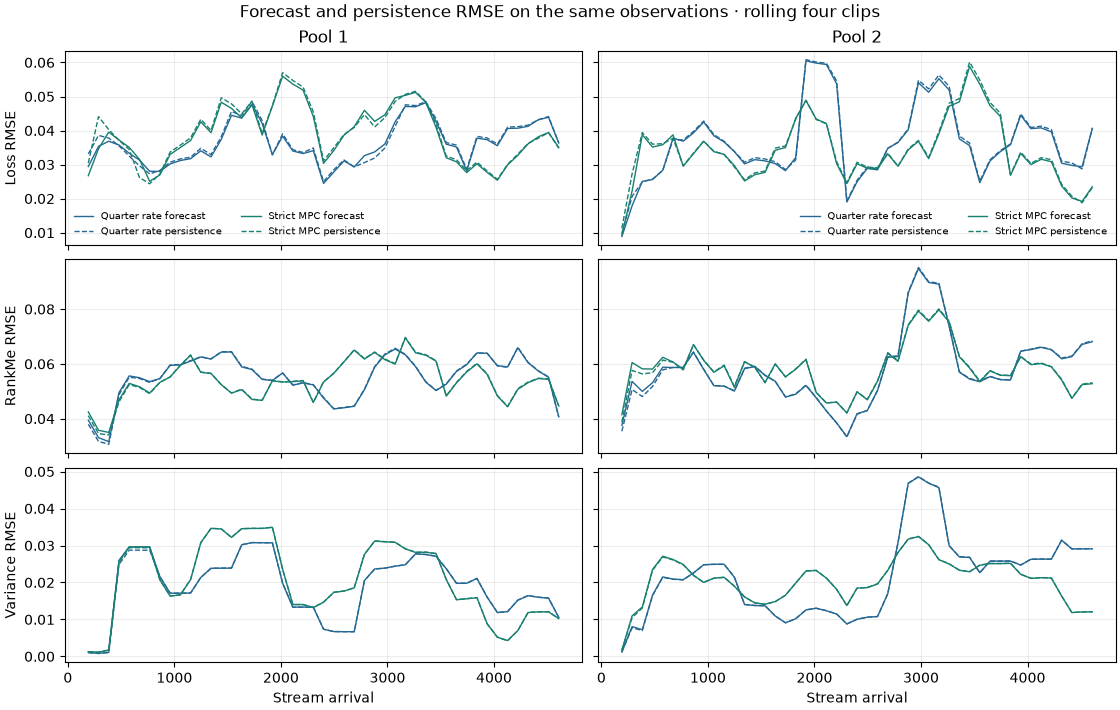

### Strict MPC action-conditioned RMSE against persistence

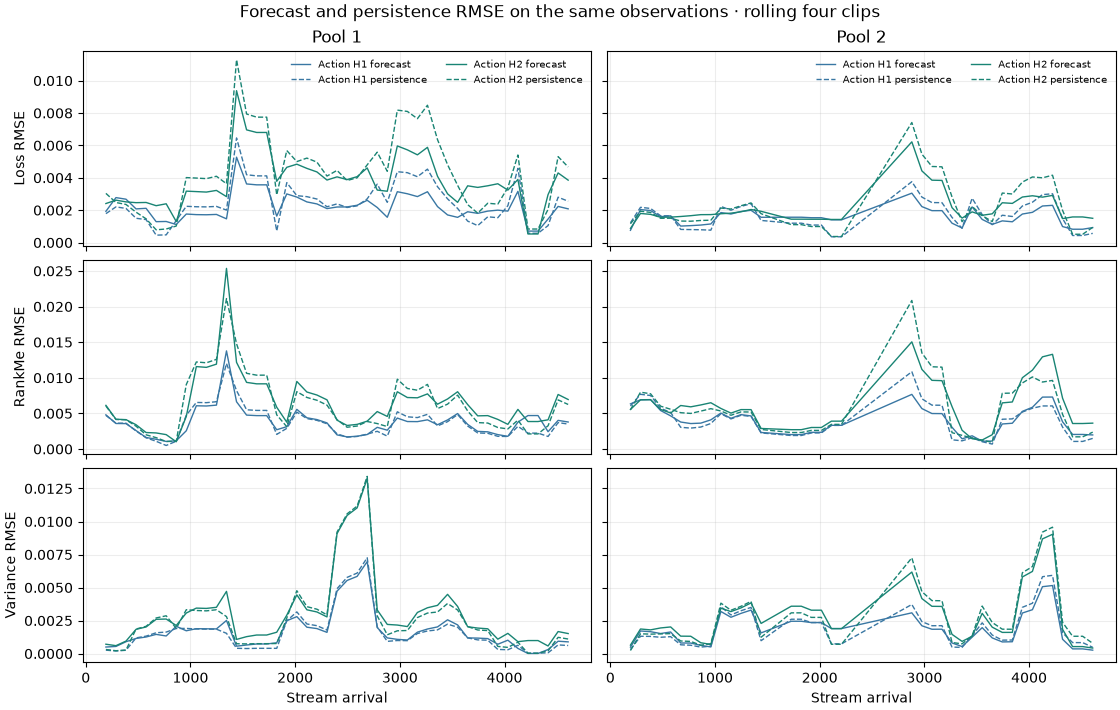